# Pine vs eucalyptus: weak labels + separability check
Run cells in order. Uses one year (2022) for PEVS, MapBiomas and AlphaEarth.

## [0] Setup

In [ ]:
import re
import pandas as pd
import ee

YEAR = 2022               # match validation points; PEVS, MapBiomas and AlphaEarth all cover it
PURITY = 0.95             # min share of planted area that is one species
MIN_AREA_HA = 1000        # skip municipalities with tiny plantation area
STATES = ["41", "42"]     # IBGE state prefixes: 41=PR, 42=SC (43=RS, 35=SP, 31=MG). [] = all
N_PER_CLASS = 150

## [1] Load PEVS table 5930 (planted area by species, per municipality)

In [ ]:
# Download from https://sidra.ibge.gov.br/tabela/5930 :
#   Variável = Área total existente em 31/12 ; Espécie florestal = Total, Eucalipto, Pinus
#   Ano = YEAR ; Unidade territorial = Município (all) ; layout: Município in rows, species in columns
#   Tick 'show territory codes' so a 'Cód.' column appears. Download as XLSX -> upload to Colab as tabela5930.xlsx
def load_sidra(path):
    raw = pd.read_excel(path, header=None)
    is_hdr = raw.astype(str).apply(lambda r: r.str.contains("Eucalipto", case=False).any(), axis=1)
    hdr = is_hdr.idxmax()
    names = raw.iloc[hdr].astype(str).str.strip().tolist()
    df = raw.iloc[hdr + 1:].copy()
    df.columns = ["code", "name"] + names[2:]
    df = df[df["code"].astype(str).str.fullmatch(r"\d{7}")]
    pick = lambda key: next(c for c in df.columns if key.lower() in str(c).lower())
    out = pd.DataFrame({
        "code": df["code"].astype(str),
        "name": df["name"],
        "total": pd.to_numeric(df[pick("Total")], errors="coerce"),   # "-" / "..." -> NaN
        "euc":   pd.to_numeric(df[pick("Eucalipto")], errors="coerce"),
        "pine":  pd.to_numeric(df[pick("Pinus")], errors="coerce"),
    }).fillna(0)
    return out

pevs = load_sidra("tabela5930.xlsx")
pevs = pevs[pevs.total >= MIN_AREA_HA]
if STATES:
    pevs = pevs[pevs.code.str[:2].isin(STATES)]

euc_codes  = pevs.loc[pevs.euc  / pevs.total >= PURITY, "code"].tolist()
pine_codes = pevs.loc[pevs.pine / pevs.total >= PURITY, "code"].tolist()
print(f"{len(euc_codes)} pure-eucalyptus, {len(pine_codes)} pure-pine municipalities")
# If one list is tiny, lower PURITY to 0.9 or add a neighbouring state.

48 pure-eucalyptus, 10 pure-pine municipalities


## [2] Sample plantation points inside those municipalities (Earth Engine)

In [ ]:
ee.Authenticate()
ee.Initialize(project="cropin-510901")

# IBGE municipal boundaries (field CD_MUN), uploaded as an asset. Download:
# https://www.ibge.gov.br/geociencias/organizacao-do-territorio/malhas-territoriais/15774-malhas.html
muni = ee.FeatureCollection("projects/cropin-510901/assets/BR_Municipios_2025")

# Use the same MapBiomas collection your team already uses; class 9 = forest plantation
lulc = ee.Image(
    "projects/mapbiomas-public/assets/brazil/lulc/collection9/mapbiomas_collection90_integration_v1"
).select(f"classification_{YEAR}")
plantation = lulc.eq(9)

emb = (ee.ImageCollection("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")
       .filterDate(f"{YEAR}-01-01", f"{YEAR + 1}-01-01").mosaic())

pine_list = ee.List(pine_codes)
sel = (muni.filter(ee.Filter.inList("CD_MUN", euc_codes + pine_codes))
       .map(lambda f: f.set({
           "cd": ee.Number.parse(f.get("CD_MUN")),
           "label": ee.Algorithms.If(pine_list.contains(f.get("CD_MUN")), 1, 0),  # 1=pine, 0=euc
       })))

label_img = ee.Image().byte().paint(sel, "label").rename("label")
muni_img = ee.Image().int32().paint(sel, "cd").rename("muni")

# Step A: find points using only the 2 small label bands, at MapBiomas's native 30 m,
# inside a simple bounding box instead of 58 merged outlines
pts = (label_img.addBands(muni_img).updateMask(plantation)
       .stratifiedSample(numPoints=N_PER_CLASS, classBand="label",
                         region=sel.geometry().bounds(), scale=30,
                         seed=42, geometries=True, tileScale=16))

# Step B: look up the 64 embedding values only at those ~300 points
pts = emb.sampleRegions(collection=pts, scale=10, geometries=True, tileScale=4)

df = ee.data.computeFeatures({"expression": pts, "fileFormat": "PANDAS_DATAFRAME"})
print("codes:", len(euc_codes + pine_codes), "| matched in boundaries:", sel.size().getInfo())
print(df.label.value_counts())

codes: 58 | matched in boundaries: 58
label
0    150
1    150
Name: count, dtype: int64


In [ ]:
# !pip install -q geemap   # only if the import fails
import geemap
from google.colab import output
output.enable_custom_widget_manager()   # lets the map display in Colab

m = geemap.Map()
m.add_basemap("SATELLITE")   # high-res imagery for spot-checking
m.addLayer(sel.style(color="yellow", fillColor="00000000"), {}, "municipalities")
m.addLayer(pts.filter(ee.Filter.eq("label", 0)), {"color": "blue"}, "eucalyptus")
m.addLayer(pts.filter(ee.Filter.eq("label", 1)), {"color": "red"}, "pine")
m.centerObject(sel, 7)
m

Map(center=[-25.4089814268068, -51.44712879477824], controls=(WidgetControl(options=['position', 'transparent_…

## [3] Spot-check ~20 points in Google Earth / high-res imagery

In [ ]:
coords = pts.limit(20).geometry().coordinates().getInfo()
for (lon, lat), lab in zip(coords, df.label[:20]):
    print(f"{lat:.5f}, {lon:.5f}  ->  {'pine' if lab == 1 else 'eucalyptus'}")

-25.22429, -49.28045  ->  eucalyptus
-27.32985, -48.69969  ->  eucalyptus
-25.03268, -49.15595  ->  eucalyptus
-24.72276, -49.44134  ->  eucalyptus
-23.67092, -50.54816  ->  eucalyptus
-25.15799, -49.34648  ->  eucalyptus
-24.43736, -51.16584  ->  eucalyptus
-27.39453, -48.89885  ->  eucalyptus
-25.00546, -49.27911  ->  eucalyptus
-24.99845, -49.21928  ->  eucalyptus
-23.57606, -50.54708  ->  eucalyptus
-27.31961, -48.80884  ->  eucalyptus
-25.10787, -49.25862  ->  eucalyptus
-28.55066, -49.12630  ->  eucalyptus
-28.13079, -48.89885  ->  eucalyptus
-23.64748, -50.52741  ->  eucalyptus
-23.58280, -51.12811  ->  eucalyptus
-24.99468, -49.29150  ->  eucalyptus
-28.12648, -49.01204  ->  eucalyptus
-25.15611, -49.41709  ->  eucalyptus


## [4] Separability check on AlphaEarth embeddings

In [ ]:
# GroupKFold by municipality so the model can't score well just by memorising places
# and stratify to keep similar proportion of pine and eucalyptus in training and testing
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

bands = [f"A{i:02d}" for i in range(64)]
X, y, groups = df[bands], df["label"], df["muni"]

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
scores = cross_val_score(LogisticRegression(max_iter=2000), X, y, groups=groups,
                         cv=cv, scoring="balanced_accuracy")
print(scores.round(2), f"mean {scores.mean():.2f}")

[0.91 1.   0.89] mean 0.93


In [ ]:
from sklearn.model_selection import cross_validate

res = cross_validate(LogisticRegression(max_iter=2000), X, y, groups=groups, cv=cv,
                     scoring=["roc_auc", "balanced_accuracy"])
for m in ["roc_auc", "balanced_accuracy"]:
    s = res[f"test_{m}"]
    print(f"{m}: {s.round(2)}  mean {s.mean():.2f}")

roc_auc: [0.98 1.   0.99]  mean 0.99
balanced_accuracy: [0.91 1.   0.89]  mean 0.93


In [ ]:
# check to see if location is driving predictions
df["lon"] = df["geo"].apply(lambda g: g["coordinates"][0])
df["lat"] = df["geo"].apply(lambda g: g["coordinates"][1])
# (from the Drive CSV instead: import json; parse df[".geo"] with json.loads first)

res_geo = cross_validate(LogisticRegression(max_iter=2000), df[["lat", "lon"]], y,
                         groups=groups, cv=cv, scoring=["roc_auc", "balanced_accuracy"])
print({m: res_geo[f"test_{m}"].mean().round(2) for m in ["roc_auc", "balanced_accuracy"]})

{'roc_auc': np.float64(0.9), 'balanced_accuracy': np.float64(0.85)}


## Cell [5]: get each point's yearly MapBiomas class history (1985–2022)

In [ ]:
HIST_YEARS = list(range(1985, YEAR + 1))
mb = ee.Image(
    "projects/mapbiomas-public/assets/brazil/lulc/collection9/mapbiomas_collection90_integration_v1"
).select([f"classification_{y}" for y in HIST_YEARS])

hist = mb.sampleRegions(collection=pts.select(["label", "muni"]), scale=30,
                        geometries=False, tileScale=4)
dfh = ee.data.computeFeatures({"expression": hist, "fileFormat": "PANDAS_DATAFRAME"})
dfh["label"] = dfh["label"].astype(int)
print(dfh.shape, dfh.label.value_counts().to_dict())

(300, 41) {0: 150, 1: 150}


## Cell [6]: turn each history into clearing features

In [ ]:
import numpy as np
from itertools import groupby

MIN_GAP = 1   # min years out of plantation to count as a clearing; try 2 to ignore one-year flicker

def harvest_features(seq):
    runs = [(k, len(list(g))) for k, g in groupby(s == 9 for s in seq)]  # (is_plantation, length)
    plant_idx = [i for i, (p, _) in enumerate(runs) if p]
    if not plant_idx:
        return dict(n_clear=0, rot_len=np.nan, yrs_plant=0, first_plant=np.nan)
    inner = runs[plant_idx[0]:plant_idx[-1] + 1]              # from first to last plantation run
    gaps = [n for p, n in inner if not p and n >= MIN_GAP]    # clearings between plantation runs
    # rotation length = plantation runs that end in a clearing (complete cycles)
    rots = [inner[i][1] for i in range(len(inner) - 1)
            if inner[i][0] and not inner[i + 1][0] and inner[i + 1][1] >= MIN_GAP]
    first = sum(n for _, n in runs[:plant_idx[0]])
    return dict(n_clear=len(gaps),
                rot_len=np.median(rots) if rots else np.nan,
                yrs_plant=int(sum(s == 9 for s in seq)),
                first_plant=HIST_YEARS[0] + first)

cols = [f"classification_{y}" for y in HIST_YEARS]
feats = pd.DataFrame([harvest_features(r) for r in dfh[cols].to_numpy()])
feats["rot_len_filled"] = feats["rot_len"].fillna(feats["yrs_plant"])  # no full cycle -> use time so far
hf = pd.concat([dfh[["label", "muni"]].reset_index(drop=True), feats], axis=1)
print(hf.groupby("label")[["n_clear", "rot_len", "yrs_plant", "first_plant"]].median())

       n_clear  rot_len  yrs_plant  first_plant
label                                          
0          0.0      4.0       13.0       2010.0
1          0.0      3.0       18.0       2005.0


## Cell [7]: box plots by species

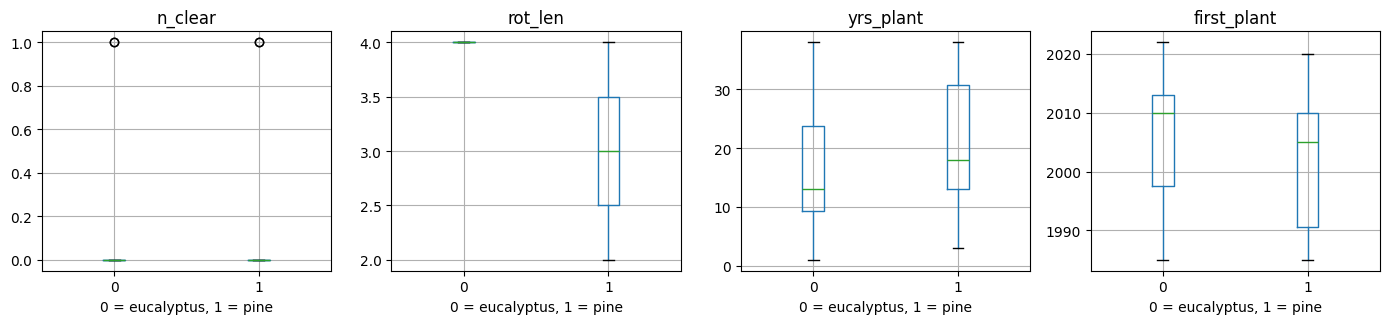

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, c in zip(axes, ["n_clear", "rot_len", "yrs_plant", "first_plant"]):
    hf.boxplot(column=c, by="label", ax=ax)
    ax.set_title(c); ax.set_xlabel("0 = eucalyptus, 1 = pine")
plt.suptitle(""); plt.tight_layout(); plt.show()

## Cell [8]: cross-validation with harvest features only, compared against the coordinates baseline

In [ ]:
from sklearn.ensemble import RandomForestClassifier
Xh = hf[["n_clear", "rot_len_filled", "yrs_plant", "first_plant"]].fillna(-1)
res_h = cross_validate(RandomForestClassifier(n_estimators=200, random_state=42),
                       Xh, hf["label"], groups=hf["muni"], cv=cv,
                       scoring=["roc_auc", "balanced_accuracy"])
for m in ["roc_auc", "balanced_accuracy"]:
    s = res_h[f"test_{m}"]; print(f"harvest {m}: {s.round(2)} mean {s.mean():.2f}")

harvest roc_auc: [0.65 0.64 0.66] mean 0.65
harvest balanced_accuracy: [0.67 0.58 0.59] mean 0.61
